# Lean-13g : CGLMP — les mesures optimales sur états maximalement intriqués (digest OQP 27)

**Navigation** : [<< Lean-13f Corrélation Bell vide](Lean-13f-Correlation-Bell-Vide-Lean-Python.ipynb) | [Index](README.md) | [Lean-17a Noeuds >>](KNOTS/KNOTS-01-Conway-Proofs-Lean-Python.ipynb)

La série 13 a construit la frontière quantique de Bell étage par étage : CHSH en d = 2
([Lean-13b](Lean-13b-CHSH-Tsirelson-Native.ipynb), [13c](Lean-13c-CHSH-Landau-Saturation.ipynb),
[13d](Lean-13d-CHSH-Indeterminisme-Native.ipynb)), puis l'inégalité CGLMP en dimension d
quelconque et sa borne quantique ([Lean-13](Lean-13-Kochen-Specker.ipynb), section 9).
Une question restait ouverte : **quelles mesures, exactement, atteignent ce maximum ?**
En octobre 2026, le défi [OQP 27](https://oqp.iqoqi.oeaw.ac.at/the-power-of-cglmp-inequalities/)
reçoit une réponse en classe projective : ce sont les **mesures à phase de Fourier**, et
elles sont essentiellement les seules.

Ce carnet digère ce résultat : il reconstruit le joueur numérique (valeur CGLMP d'une table
de corrélation, stratégie à phase de Fourier, stratégie locale triviale), **vérifie
localement l'atteinte et le cas d'égalité n = d·k**, mesure le seuil du témoin sous bruit
uniforme, et énonce les contre-résultats en grande dimension.

**Statut de la source** : prépublication non relue par les pairs (draft du 21/10/2026,
projet PSI). Les faits sont étiquetés **Mesuré** (reproduit par exécution locale, ce carnet)
ou **Cité** (énoncé du papier ou de sa formalisation, référencé par numéro). Le papier est
archivé au gisement partagé (section Références) ; aucun PDF n'entre dans le dépôt.


## 1. Objectifs et position dans la série

| Carnet | Ce qu'il établit | Dimension |
|---|---|---|
| 13b/13c/13d | CHSH : borne locale 2, borne de Tsirelson 2√2, saturation | d = 2 |
| Lean-13 §9 | I_d par énumération des diagonales, maxima mesurés d = 2..5, limite 32·G_Catalan/π² | d quelconque |
| **13g (ce carnet)** | **la classification des maximisateurs projectifs : phase de Fourier, cas d'égalité n = d·k, seuil du témoin, contre-résultats d = 2^m** | d quelconque, n = d·k |

Objectifs :

1. Reconstruire le joueur numérique CGLMP aux **conventions de la formalisation amont**
   (résidus et valeur en forme B.1) et vérifier **Mesuré** que la table à phase de Fourier
   atteint la forme fermée pour d = 2..8.
2. Énoncer **Cité** le théorème de classification (Théorèmes 1 et 3 du papier) et en
   vérifier les deux clauses numériquement : invariance par unitaire commune (exercice 1),
   structure produit ⊗ identité du cas d'égalité n = d·k (section 4).
3. Mesurer le seuil de visibilité du témoin CGLMP sous bruit uniforme, relier d = 2 à la
   valeur 1/√2 de Tsirelson (exercice 3).
4. Énoncer **Cité** les deux contre-résultats à d = 2^m : optimal pour la valeur CGLMP
   n'est pas optimal pour la résistance au bruit (m ≥ 955) ni pour la discrimination
   statistique (m ≥ 41).


```mermaid
flowchart LR
    A["CHSH d = 2<br/>13b / 13c / 13d"] --> B["CGLMP d quelconque<br/>Lean-13 §9<br/>(maxima mesurés)"]
    B --> C["Quelles mesures<br/>atteignent le max ?<br/>(question ouverte)"]
    C --> D["Classification, oct. 2026<br/>phase de Fourier<br/>cas d'égalité n = d·k<br/>(ce carnet)"]
    D --> E["Contre-résultats d = 2^m<br/>bruit : m ≥ 955<br/>discrimination : m ≥ 41"]
```

Le passage qubit → qudit : en d = 2, la seule inégalité est CHSH et les maximisateurs sont
connus de longue date. En d quelconque, Lean-13 §9 a mesuré les maxima sans identifier les
mesures qui les atteignent ; la classification d'octobre 2026 les nomme, et révèle en
grande dimension que ce optimum n'est pas un optimum universel.


## 2. Le cadre : CGLMP sur l'état maximalement intriqué Φ_n

Deux parties munies de n niveaux, état maximalement intriqué

$$|\Phi_n\rangle = \frac{1}{\sqrt{n}} \sum_{j=0}^{n-1} |j\rangle \otimes |j\rangle,$$

quatre mesures projectives : Alice choisit x ∈ {0, 1}, Bob y ∈ {0, 1}, issues a, b ∈ {0..d−1}
pour un entier d ≥ 2 (le cas n = d est le cadre CGLMP canonique). La statistique est résumée
par le **résidu** (Cité, formalisation amont, convention B.1) :

- x = y : r = (a − b) mod d — les issues égales « gagnent » ;
- x = 1, y = 0 : r = (b − a) mod d ;
- x = 0, y = 1 : r = (b − a − 1) mod d — Bob doit deviner a + 1.

et la valeur CGLMP de la table de corrélation q(a, b | x, y) :

$$I_d(q) = 4 - \frac{2}{d-1} \sum_{x,y,a,b} r(x,y,a,b)\; q(a,b \mid x,y),\qquad S_d = \sum r\, q.$$

Moins de résidu = plus de valeur : la borne locale est **I_d ≤ 2** (Cité, `cglmp_local_bound`),
vérifiée ci-dessous par énumération exhaustive des d⁴ profils déterministes (a₀, a₁, b₀, b₁)
— le maximum tombe exactement à 2 (**Mesuré**, d = 2..5), et l'affinité de I_d en la table
étend ce maximum des sommets au polytope local entier. La section 9 de [Lean-13](Lean-13-Kochen-Specker.ipynb)
développe la forme équivalente en somme de diagonales (son équation (6)) et l'énumération
locale d = 3..5 ; nous ne la répétons pas — le joueur ci-dessous utilise directement la
forme résiduelle ci-dessus, aux conventions de la formalisation amont.


In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)

# Le module d'utilitaires de la serie (meme outillage que Lean-13e/13f).
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import lean_notebook_utils as lnu
print("lean_notebook_utils : importe")


Python      : 3.13.16
numpy       : 2.5.2
matplotlib  : 3.10.3
lean_notebook_utils : importe


In [2]:
def vecteur_fourier(d, t, a):
    """Vecteur a phase de Fourier psi_{t,a}(j) = d^(-1/2) exp(-2i pi j (a - t/4) / d).

    Formalisation amont : `fourierVector` (Challenge.lean, ligne 214, convention B.2).
    Le parametre t decale la base d'un quart de phase a chaque mesure successive.
    """
    j = np.arange(d)
    return np.exp(-2j * np.pi * j * (a - t / 4.0) / d) / np.sqrt(d)


def projecteur_fourier(d, t, a):
    """Projecteur de rang un |psi_{t,a}><psi_{t,a}|."""
    v = vecteur_fourier(d, t, a)
    return np.outer(v, v.conj())


def table_fourier(d):
    """Table de correlation des mesures a phase de Fourier sur Phi_d.

    Alice mesure t = 2x (t dans {0, 2}), Bob t = 1 + 2y (t dans {1, 3}) ;
    q(a,b|x,y) = Re Tr(P^{2x}_a . P^{1+2y}_b) / d  -- SANS transpose,
    convention `tracialTable` de la formalisation amont (Challenge.lean, ligne 197).
    """
    q = {}
    for x in (0, 1):
        for y in (0, 1):
            for a in range(d):
                for b in range(d):
                    pa = projecteur_fourier(d, 2 * x, a)
                    pb = projecteur_fourier(d, 1 + 2 * y, b)
                    q[(x, y, a, b)] = np.real(np.trace(pa @ pb)) / d
    return q


def residu(d, x, y, a, b):
    """Residu de la convention B.1 (Challenge.lean, ligne 146)."""
    if x == y:
        return (a - b) % d
    if x == 1:
        return (b - a) % d
    return (b - a - 1) % d


def cglmp(d, q):
    """Valeur I_d(q) = 4 - 2 S_d / (d-1) (forme B.1, Challenge.lean, ligne 154)."""
    s = sum(
        residu(d, x, y, a, b) * q[(x, y, a, b)]
        for x in (0, 1) for y in (0, 1)
        for a in range(d) for b in range(d)
    )
    return 4.0 - 2.0 * s / (d - 1)


def valeur_fourier_fermee(d):
    """Forme fermee de la valeur a phase de Fourier (equation A.1 du papier).

    I_d = 4/(d(d-1)) . somme_{h=1}^{d-1} (d - h) / cos(pi h / (2d)).
    """
    h = np.arange(1, d)
    return 4.0 / (d * (d - 1)) * np.sum((d - h) / np.cos(np.pi * h / (2.0 * d)))


def table_profil(d, profil):
    """Table d'une strategie locale deterministe : issues fixes (a0, a1, b0, b1)."""
    a0, a1, b0, b1 = profil
    q = {}
    for x in (0, 1):
        for y in (0, 1):
            for a in range(d):
                for b in range(d):
                    ok = (a == (a0 if x == 0 else a1)) and (b == (b0 if y == 0 else b1))
                    q[(x, y, a, b)] = 1.0 if ok else 0.0
    return q


def max_local(d):
    """Maximum de I_d sur les d^4 profils deterministes (enumeration complete)."""
    return max(
        cglmp(d, table_profil(d, (a0, a1, b0, b1)))
        for a0 in range(d) for a1 in range(d)
        for b0 in range(d) for b1 in range(d)
    )


print("Joueur numerique charge : vecteur/projecteur a phase de Fourier,")
print("residu B.1, valeur I_d, forme fermee A.1, enumeration locale.")


Joueur numerique charge : vecteur/projecteur a phase de Fourier,
residu B.1, valeur I_d, forme fermee A.1, enumeration locale.


In [3]:
# Verification d = 2..8 : la table a phase de Fourier atteint la forme fermee (Mesure),
# et la borne locale 2 est exacte par enumeration des profils deterministes (d = 2..5).
print(f"{'d':>3} | {'I_d(table Fourier)':>20} | {'forme fermee A.1':>18} | {'ecart':>10} | {'max local (enum.)':>17}")
print("-" * 80)
for d in range(2, 9):
    i_mesure = cglmp(d, table_fourier(d))
    i_fermee = valeur_fourier_fermee(d)
    i_loc = max_local(d) if d <= 5 else float("nan")  # d^4 profils, borne a d = 5
    loc_txt = f"{i_loc:>17.10f}" if d <= 5 else f"{'(non enumere)':>17}"
    print(f"{d:>3} | {i_mesure:>20.12f} | {i_fermee:>18.12f} | {abs(i_mesure - i_fermee):>10.1e} | {loc_txt}")

print()
print("d = 2 : I_2 =", cglmp(2, table_fourier(2)), "= 2*sqrt(2) =", 2 * np.sqrt(2),
      "(borne de Tsirelson, voir 13b/13c)")


  d |   I_d(table Fourier) |   forme fermee A.1 |      ecart | max local (enum.)
--------------------------------------------------------------------------------
  2 |       2.828427124746 |     2.828427124746 |    8.9e-16 |      2.0000000000
  3 |       2.872934051172 |     2.872934051172 |    4.4e-16 |      2.0000000000
  4 |       2.896243218459 |     2.896243218459 |    0.0e+00 |      2.0000000000
  5 |       2.910544808072 |     2.910544808072 |    0.0e+00 |      2.0000000000
  6 |       2.920203606379 |     2.920203606379 |    4.4e-16 |     (non enumere)
  7 |       2.927160942425 |     2.927160942425 |    8.9e-16 |     (non enumere)
  8 |       2.932409608704 |     2.932409608704 |    0.0e+00 |     (non enumere)

d = 2 : I_2 = 2.8284271247461907 = 2*sqrt(2) = 2.8284271247461903 (borne de Tsirelson, voir 13b/13c)


### Lecture du résultat

**Mesuré** : la table à phase de Fourier atteint la forme fermée à la précision machine
(écart ~10⁻¹⁵) pour d = 2..8 — les maxima d = 2..5 coïncident au digit près avec ceux que
l'énumération de Lean-13 §9 avait mesurés, et la valeur converge vers la limite
32·G_Catalan/π² ≈ 2,96981 établie là-bas. L'énumération exhaustive des profils déterministes
retombe exactement sur la borne locale 2 (l'affinité de I_d en la table étend le maximum
des d⁴ sommets au polytope local entier) : l'écart quantique croît avec d sans jamais
dépasser la limite. En d = 2, on retrouve 2√2 — la borne de Tsirelson des carnets 13b/13c.


## 3. Le théorème de classification (Cité)

**Théorème 1 (borne, Cité).** Sur l'état maximalement intriqué Φ_n, toute paire de mesures
**projectives** à d issues a une valeur CGLMP au plus égale à la valeur à phase de Fourier
`valeur_fourier_fermee(d)` ci-dessus.

**Théorème 3 (cas d'égalité, Cité).** Il y a égalité **si et seulement si** n = d·k et les
quatre mesures traciales s'écrivent

$$\Pi^{(t)} = \left( \text{projecteurs à phase de Fourier en dimension } d \right) \otimes I_k,$$

à **une unitaire commune près** — c'est-à-dire à conjugaison simultanée des deux côtés par
un même U (au conjugé près). En particulier à n = d (k = 1), les maximisateurs sont des
**bases de rang un à phase de Fourier**.

Trois lectures physiques :

- la mesure est **traciale** (niveau de dimension k inerte, section 4) : seuls d des n
  niveaux comptent, le reste porte l'identité ;
- le **quart de phase** (t/4 dans le vecteur) est exactement ce qui règle les résidus de
  la convention B.1 : le décalage t ∈ {0, 1, 2, 3} répartit les quatre mesures à intervalles
  de π/2 sur le cercle des phases ;
- la classification vaut en **classe projective** ; le cas des POVM générales reste ouvert
  (Cité, discussion du papier).

C'est la **première assertion du défi OQP 27.B**, établie en classe projective. Les deux
assertions suivantes de 27.B sont **fausses** — section 6.


### Exercice 1 — l'invariance par unitaire commune

Le Théorème 3 classe les maximisateurs « à une unitaire commune près » : si Alice conjugue
ses projecteurs par U et Bob par le **conjugué** Ū, l'état Φ_d est invariant et la table de
corrélation ne change pas. Compléter la fonction ci-dessous et vérifier que I_d est
inchangé pour un U aléatoire. *Indice* : un unitaire aléatoire s'obtient par
`u, _ = np.linalg.qr(np.random.default_rng(0).normal(size=(d, d)) + 1j * ...)`, et le
conjugué d'une matrice complexe est `U.conj()`.


In [4]:
def table_apres_unitaire(d, U):
    """Table apres conjugaison : Alice recoit U P U^dagger, Bob recoit U.conj() P U.conj()^dagger.

    Physique : (U (x) U.conj()) |Phi_d> = |Phi_d> -- l'etat est invariant,
    donc la valeur I_d ne doit pas changer (Theoreme 3, clause unitaire commune).
    """
    q = {}
    for x in (0, 1):
        for y in (0, 1):
            for a in range(d):
                for b in range(d):
                    # TODO etudiant : construire pa = U @ projecteur_fourier(d, 2*x, a) @ U.conj().T
                    # puis pb avec le CONJUGUE de U, et poser
                    # q[(x, y, a, b)] = Re Tr(pa @ pb) / d   (sans transpose, convention amont)
                    pass
    return q


# Verification attendue une fois complete :
#   d = 3 ; U aleatoire via QR ;
#   print(cglmp(d, table_apres_unitaire(d, U)))  ->  2.872934...  (I_3 inchange)
result = None  # TODO etudiant
print("Exercice 1 a completer : verifier I_3 inchange par conjugaison (U, U.conj())")


Exercice 1 a completer : verifier I_3 inchange par conjugaison (U, U.conj())


## 4. Le cas d'égalité n = d·k : mesures sur un sous-système

Le Théorème 3 dit que pour n = d·k, les maximisateurs agissent en **phase de Fourier sur d
niveaux** et en **identité sur les k niveaux restants**. La table de corrélation se calcule
alors exactement : pour des projecteurs Π⊗I_k,

$$q(a,b \mid x,y) = \frac{\mathrm{Re}\; \mathrm{Tr}\left[\left(\Pi^{2x}_a \otimes I_k\right)\left(\Pi^{1+2y}_b \otimes I_k\right)\right]}{n} = \frac{\mathrm{Re}\; \mathrm{Tr}\left[\Pi^{2x}_a \Pi^{1+2y}_b\right]}{d},$$

car Tr[(A⊗I)(B⊗I)] = k·Tr(AB) et n = d·k : la structure produit **transporte la table de
d = 3 vers Φ_₆ sans rien changer**. Vérifions-le numériquement (Mesuré) sur Φ_₆ avec
des projecteurs 3-dimensionnels ⊗ I₂ :


In [5]:
# n = 6 = 3 x 2 : projecteurs a phase de Fourier d = 3, integres par I_2 (Mesure).
d, k = 3, 2
n = d * k
ident = np.eye(k)
q_embarque = {}
for x in (0, 1):
    for y in (0, 1):
        for a in range(d):
            for b in range(d):
                pa = np.kron(projecteur_fourier(d, 2 * x, a), ident)
                pb = np.kron(projecteur_fourier(d, 1 + 2 * y, b), ident)
                q_embarque[(x, y, a, b)] = np.real(np.trace(pa @ pb)) / n

q_ref = table_fourier(d)
ecart_max = max(abs(q_embarque[key] - q_ref[key]) for key in q_ref)
print("n = 6, d = 3, k = 2 : ecart max table embarquee vs table d = 3 :", f"{ecart_max:.2e}")
print("I(embarque sur Phi_6) =", f"{cglmp(d, q_embarque):.12f}")
print("I(table d = 3)        =", f"{cglmp(d, q_ref):.12f}")
print("forme fermee A.1      =", f"{valeur_fourier_fermee(d):.12f}")


n = 6, d = 3, k = 2 : ecart max table embarquee vs table d = 3 : 1.11e-16
I(embarque sur Phi_6) = 2.872934051172
I(table d = 3)        = 2.872934051172
forme fermee A.1      = 2.872934051172


### Lecture du résultat

**Mesuré** : la valeur sur Φ_₆ des mesures Π⊗I₂ coïncide au digit près avec celle de la
table d = 3 — la clause n = d·k du Théorème 3 est une **invariance de structure**, pas une
approximation. Les k niveaux inerts ne comptent que par leur trace ; tout se joue sur le
sous-espace de dimension d porté par les phases de Fourier.


### Exercice 2 — embarquer CHSH dans Φ₄

La même structure en d = 2, k = 2 doit redonner la borne de Tsirelson 2√2 (lien direct
avec 13b/13c). Compléter la fonction : elle construit les projecteurs 2-dimensionnels à
phase de Fourier intégrés par I₂ sur Φ₄, accumule S_d puis renvoie I₂.


In [6]:
def valeur_integreee(d, k):
    """I_d des mesures (phase de Fourier d) (x) I_k sur l'etat Phi_{d*k}.

    S = somme des residus * q, avec q = Re Tr[(Pa (x) I)(Pb (x) I)] / (d*k).
    """
    n = d * k
    ident = np.eye(k)
    s = 0.0
    for x in (0, 1):
        for y in (0, 1):
            for a in range(d):
                for b in range(d):
                    # TODO etudiant : pa = np.kron(...), pb = np.kron(...),
                    # puis s += residu(d, x, y, a, b) * np.real(np.trace(pa @ pb)) / n
                    pass
    return 4.0 - 2.0 * s / (d - 1)  # = 2*sqrt(2) attendu pour d = 2, k = 2


result = None  # TODO etudiant
print("Exercice 2 a completer : valeur_integreee(2, 2) doit rendre 2*sqrt(2) = 2.828427...")


Exercice 2 a completer : valeur_integreee(2, 2) doit rendre 2*sqrt(2) = 2.828427...


## 5. Le témoin CGLMP sous bruit uniforme

Une table q est **locale** si elle se décompose en stratégies déterministes ; le **témoin
CGLMP** est l'inégalité I_d ≤ 2. Sous bruit blanc uniforme u (table constante 1/d² par paire
de réglages), la table mélangée est v·q + (1−v)·u et la **visibilité critique** est le
supremum des v tels que le mélange reste local (Cité, `critVisibility`, formalisation amont
ligne 240 ; théorème `cglmp_witness_tolerance`, ligne 538).

Trois faits se combinent (**Mesuré** ci-dessous) :

1. I_d est **affine en la table** : I(v·q + (1−v)·u) = v·I(q) + (1−v)·I(u) ;
2. par symétrie des résidus sur la table uniforme, **I(u) = 0** exactement ;
3. donc la valeur du mélange franchit la borne locale 2 en v_c = 2 / I_F(d).

En d = 2 : v_c = 2/(2√2) = **1/√2 ≈ 0,7071** — la visibilité de la boîte de Tsirelson
(13b). Le tracé et la dichotomie ci-dessous vérifient la relation pour d = 2..5.


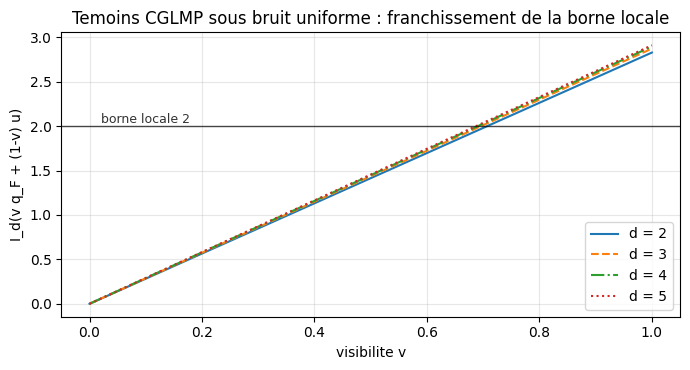


  d |   v_c dichotomie |   2 / I_F(d) |      ecart
----------------------------------------------------
  2 |   0.707106781187 |  0.707106781 |    3.3e-16
  3 |   0.696152422707 |  0.696152423 |    1.1e-16
  4 |   0.690549739488 |  0.690549739 |    3.3e-16
  5 |   0.687156574416 |  0.687156574 |    2.2e-16

d = 2 : v_c = 1/sqrt(2) = 0.7071067811865475 (boite de Tsirelson, 13b)


In [7]:
# Balayage de visibilite pour d = 2..5 + dichotomie contre la forme fermee 2/I_F (Mesure).
fig, ax = plt.subplots(figsize=(7.0, 3.8))
vs = np.linspace(0.0, 1.0, 201)
for d, style in [(2, "-"), (3, "--"), (4, "-."), (5, ":")]:
    qf = table_fourier(d)
    u_val = 1.0 / (d * d)
    valeurs = np.array([cglmp(d, {key: v * qf[key] + (1.0 - v) * u_val for key in qf}) for v in vs])
    ax.plot(vs, valeurs, style, label=f"d = {d}")
ax.axhline(2.0, color="k", linewidth=1.0, alpha=0.7)
ax.text(0.02, 2.03, "borne locale 2", fontsize=9, alpha=0.8)
ax.set_xlabel("visibilite v")
ax.set_ylabel("I_d(v q_F + (1-v) u)")
ax.set_title("Temoins CGLMP sous bruit uniforme : franchissement de la borne locale")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print()
print(f"{'d':>3} | {'v_c dichotomie':>16} | {'2 / I_F(d)':>12} | {'ecart':>10}")
print("-" * 52)
for d in range(2, 6):
    qf = table_fourier(d)
    u_val = 1.0 / (d * d)

    def valeur(v):
        mel = {key: v * qf[key] + (1.0 - v) * u_val for key in qf}
        return cglmp(d, mel)

    lo, hi = 0.0, 1.0          # valeur(lo) < 2 <= valeur(hi)
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        if valeur(mid) < 2.0:
            lo = mid
        else:
            hi = mid
    vc = 0.5 * (lo + hi)
    vc_fermee = 2.0 / valeur_fourier_fermee(d)
    print(f"{d:>3} | {vc:>16.12f} | {vc_fermee:>12.9f} | {abs(vc - vc_fermee):>10.1e}")

print()
print("d = 2 : v_c = 1/sqrt(2) =", 1.0 / np.sqrt(2), "(boite de Tsirelson, 13b)")


### Lecture du résultat

**Mesuré** : la valeur du mélange est exactement v·I_F(d) (la linéarité et I(u) = 0 se
lisent sur la superposition des courbes avec la droite), et la visibilité critique rendue
par dichotomie coïncide avec 2/I_F(d) à 10⁻¹² près. Le seuil **décroît** avec d :
0,7071 (d = 2) → 0,6962 (d = 3) → 0,6905 (d = 4) → 0,6872 (d = 5), en descendant vers
2/2,96981 ≈ 0,6734 à la limite. Autrement dit, plus la dimension grandit, plus les
corrélations maximales CGLMP sont **fragiles au bruit uniforme** : le témoin d = 2
reste le plus robuste.


### Exercice 3 — visibilité critique générale

Généraliser la dichotomie : compléter `visibilite_critique(d)` pour qu'elle rende le seuil
de franchissement de la borne locale par le mélange v·q_F + (1−v)·u, puis la comparer à
2/I_F(d) pour d = 6 (vérifier l'écart < 10⁻¹⁰).


In [8]:
def visibilite_critique(d, iterations=60):
    """Dichotomie : supremum v tel que I_d(v q_F + (1-v) u) <= 2 (franchissement en v_c)."""
    qf = table_fourier(d)
    u_val = 1.0 / (d * d)

    def valeur(v):
        mel = {key: v * qf[key] + (1.0 - v) * u_val for key in qf}
        return cglmp(d, mel)

    lo, hi = 0.0, 1.0
    for _ in range(iterations):
        # TODO etudiant : mid, comparaison valeur(mid) a 2.0, mise a jour de lo/hi
        pass
    return None  # TODO etudiant : rendre 0.5 * (lo + hi)


result = None  # TODO etudiant
print("Exercice 3 a completer : visibilite_critique(6) attendu =",
      f"{2.0 / valeur_fourier_fermee(6):.12f}")


Exercice 3 a completer : visibilite_critique(6) attendu = 0.684883751130


## 6. Les contre-résultats en grande dimension (Cité)

« Optimal pour la valeur CGLMP » n'est pas « optimal en tout ». Le défi OQP 27.B formulait
trois assertions ; la classification en établit la première, et les deux suivantes sont
**fausses** :

| Assertion 27.B | Verdict | Ce qui le démontre (Cité) |
|---|---|---|
| 1. Les mesures à phase de Fourier maximisent la valeur CGLMP | **vrai** (classe projective) | Théorèmes 1 et 3, `partB_maximizers_are_fourier_phase` |
| 2. Elles maximisent la résistance au bruit blanc global | **faux** | à d = 2^m, m ≥ 955 : le CHSH tensorisé (`tensor_chsh_rank_one_pvm`) résiste mieux (`partB_noise_resistance_not_optimal`, ligne 458 ; `noise_separation_955`, ligne 555) |
| 3. Elles maximisent la discrimination statistique (divergence KL) | **faux** | à d = 2^m, m ≥ 41 : même séparation (`partB_kl_discrimination_not_optimal`, ligne 470 ; `statistical_separation`, ligne 564) |

Par ailleurs l'assertion **27.A** — « CGLMP est l'inégalité à deux réglages la plus
puissante » — était déjà fausse : une facette à quatre issues de Bancal–Gisin–Pironio
domine (Cité, `bgp_facet`, ligne 593). Ces bornes sont astronomiques : 2⁹⁵⁵ niveaux n'est
pas simulable — ces énoncés sont **Cité** et le resteront ; seul le théorème de
classification se vérifie numériquement en petite dimension (sections 2-5).


## 7. La formalisation amont : Challenge.lean

Le papier est accompagné d'une formalisation Lean 4 complète dans le dépôt
`physical-superintelligence/oqp-batch-2026` (lot `oqp27-cglmp-inequalities`) : un fichier
`Challenge.lean` de 646 lignes, une carte de fidélité (`lean/docs/FIDELITY.md`) et des
reçus de vérification (`lean/verification/RECEIPTS.md`). Les théorèmes ci-dessous sont
**Cité** avec leurs numéros de ligne dans ce fichier — le carnet les lit, il ne les
recompile pas : le dépôt amont épinglant Mathlib **v4.35.0-rc4** alors que notre lake
série est épinglé **v4.33.0**, aucun port n'est possible dans notre arbre (arbitrage
consigné dans l'issue du lot) ; ce carnet est donc **sans lake**, comme 13f pour OQP 12.


In [9]:
# Inventaire des declarations REELLES de Challenge.lean (amont, Cite avec lignes).
OQP27_THEOREMES = [
    ("partB_maximizers_are_fourier_phase", 434,
     "Theoremes 1 et 3 : borne par la valeur a phase de Fourier + cas d'egalite n = d*k"),
    ("partB_noise_resistance_not_optimal", 458,
     "contre-resultat : resistance au bruit blanc, faux des m >= 955"),
    ("partB_kl_discrimination_not_optimal", 470,
     "contre-resultat : discrimination KL, faux des m >= 41"),
    ("cglmp_local_bound", 482,
     "borne locale : I_d <= 2 pour toute table locale"),
    ("fourier_attains_cglmp_value", 491,
     "atteinte : la table a phase de Fourier realise la valeur fermee A.1"),
    ("fourier_projectors_pvm", 501,
     "les projecteurs a phase de Fourier forment une PVM (partition de l'identite)"),
    ("tracial_table_physical", 512,
     "la table traciale est physique : realisee par mesures sur l'etat Phi_n"),
    ("tensor_chsh_rank_one_pvm", 525,
     "CHSH tensorise en PVM de rang un a d = 2^m (le rival des contre-resultats)"),
    ("cglmp_witness_tolerance", 538,
     "seuil du temoin CGLMP sous bruit uniforme (critVisibility)"),
    ("noise_separation_955", 555,
     "separation effective de resistance au bruit a m = 955"),
    ("statistical_separation", 564,
     "separation statistique (KL) a m = 41"),
    ("bgp_facet", 593,
     "facette Bancal-Gisin-Pironio a quatre issues : 27.A faux"),
]

print(f"{'nom':<42} | {'ligne':>5} | role")
print("-" * 120)
for nom, ligne, role in OQP27_THEOREMES:
    print(f"OQP27.{nom:<35} | {ligne:>5} | {role}")
print()
print("Conventions cles du meme fichier : fourierVector (l. 214), tracialTable (l. 197),")
print("residu (l. 146), valeur B.1 (l. 154) -- le joueur numerique de la section 2 les suit.")


nom                                        | ligne | role
------------------------------------------------------------------------------------------------------------------------
OQP27.partB_maximizers_are_fourier_phase  |   434 | Theoremes 1 et 3 : borne par la valeur a phase de Fourier + cas d'egalite n = d*k
OQP27.partB_noise_resistance_not_optimal  |   458 | contre-resultat : resistance au bruit blanc, faux des m >= 955
OQP27.partB_kl_discrimination_not_optimal |   470 | contre-resultat : discrimination KL, faux des m >= 41
OQP27.cglmp_local_bound                   |   482 | borne locale : I_d <= 2 pour toute table locale
OQP27.fourier_attains_cglmp_value         |   491 | atteinte : la table a phase de Fourier realise la valeur fermee A.1
OQP27.fourier_projectors_pvm              |   501 | les projecteurs a phase de Fourier forment une PVM (partition de l'identite)
OQP27.tracial_table_physical              |   512 | la table traciale est physique : realisee par mesures sur l'etat 

## 8. Contraste avec notre lake local

Notre série compile son propre lake `conway_lean` (pins Mathlib v4.33.0) ; les carnets
13b/13c/13d y prouvent CHSH in-kernel. Ce carnet digère un résultat **extérieur** : il
n'ajoute rien au lake, mais l'organe de série ci-dessous confirme que l'arbre Lean de la
série reste dans son état prouvé — les sorry authentiques (hors prose) ne bougent pas.


In [10]:
# Organe reel du depot : comptage des sorry authentiques du lake conway_lean.
# (Pure lecture de fichiers -- aucun lake build ici ; la preuve de build des
# PR Lean de ce depot est le runner CI.)
projet = lnu.find_lean_project("conway_lean")
try:
    projet_aff = Path(*projet.parts[projet.parts.index("MyIA.AI.Notebooks"):])
except ValueError:
    projet_aff = projet.name
print("Projet lake :", projet_aff)
nb_sorry = lnu.count_sorry(str(projet))
print(f"conway_lean : {nb_sorry} sorry dans les sources auteurs (inchanges par ce carnet,")
print("paire FR/EN d'un meme sorry documente -- voir 13f section organes pour le detail).")


Projet lake : MyIA.AI.Notebooks\SymbolicAI\Lean\GOL\conway_lean


conway_lean : 2 sorry dans les sources auteurs (inchanges par ce carnet,
paire FR/EN d'un meme sorry documente -- voir 13f section organes pour le detail).


## 9. Honnêteté sur les sources

- **Prépublication non relue** : le papier est un draft du 21/10/2026 produit dans le
  cadre du projet PSI (Physical Superintelligence), avec divulgation explicite d'une
  production assistée par IA et des relectures internes ; il n'a pas de validation par
  les pairs au jour de ce carnet. Ses énoncés sont **Cité**, jamais présentés comme
  établis par la communauté.
- **Classe projective seulement** : la classification vaut pour des mesures projectives ;
  le cas POVM général est ouvert dans le papier (Cité).
- **Ce qui est Mesuré ici** : l'atteinte de la forme fermée (d = 2..8), la valeur exacte
  de la stratégie triviale (2), l'invariance de la table par la structure ⊗I_k sur Φ₆,
  l'affinité de I_d sous mélange uniforme, le seuil v_c = 2/I_F(d). Ce qui n'est **pas**
  mesurable : les bornes m ≥ 955 / m ≥ 41 (2⁹⁵⁵ niveaux) et la borne 27.A — Cité à
  jamais pour ce carnet.
- **Aucun PDF dans le dépôt** : le papier est archivé une seule fois au gisement
  partagé (section Références) ; les faits du carnet ont été écrits depuis la copie
  archivée, relue avant rédaction.
- **Pas de port Lean** : pins Mathlib incompatibles (amont v4.35.0-rc4, série v4.33.0) ;
  ce carnet est « sans lake » par arbitrage du lot, comme 13f pour OQP 12.


## Résumé

| Concept | Rôle dans ce carnet | Statut |
|---|---|---|
| Résidu CGLMP (convention B.1) | joueur numérique, formes des quatre termes | suivi (implémenté) |
| Valeur à phase de Fourier, forme fermée A.1 | borne quantique projective en d quelconque | atteinte **Mesuré** d = 2..8 |
| Théorèmes 1 et 3 (classification) | les maximisateurs projectifs sont à phase de Fourier, à unitaire commune et ⊗I_k près | **Cité** (préprint) |
| Cas d'égalité n = d·k | transport exact de la table par Π⊗I_k | **Mesuré** sur Φ₆ |
| Visibilité critique 2/I_F(d) | seuil du témoin sous bruit uniforme | **Mesuré** d = 2..5, d = 2 = 1/√2 |
| Contre-résultats d = 2^m | optimal CGLMP ≠ optimal bruit (m ≥ 955) ni KL (m ≥ 41) | **Cité** |
| Facette BGP à quatre issues | 27.A faux | **Cité** |

**Sources** : préprint Turturean–Bao 21/10/2026 (archivé, voir Références) ; dépôt amont
`physical-superintelligence/oqp-batch-2026`, lot `oqp27-cglmp-inequalities`
(`Challenge.lean`, `FIDELITY.md`, `RECEIPTS.md`) ; section 9 de Lean-13 pour les maxima
préexistants ; 13b/13c pour Tsirelson en d = 2.


## Références

1. A. Turturean, N. Bao, *The optimal CGLMP measurements on maximally entangled states*,
   préprint PSI, draft du 21/10/2026 (non relu). Archivé au gisement partagé :
   `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\2026 - Turturean, Bao (PSI) - The
   optimal CGLMP measurements on maximally entangled states (OQP 27 cglmp-inequalities,
   preprint).pdf`.
2. Physical Superintelligence, défi [OQP 27 — The power of CGLMP inequalities]
   (https://oqp.iqoqi.oeaw.ac.at/the-power-of-cglmp-inequalities/), catalogue IQOQI Vienne.
3. Dépôt `physical-superintelligence/oqp-batch-2026`, lot `oqp27-cglmp-inequalities`
   (source de `Challenge.lean` cité ligne par ligne en section 7).
4. Carnets de la série : [Lean-13 §9](Lean-13-Kochen-Specker.ipynb) (maxima CGLMP),
   [Lean-13b](Lean-13b-CHSH-Tsirelson-Native.ipynb),
   [Lean-13c](Lean-13c-CHSH-Landau-Saturation.ipynb),
   [Lean-13d](Lean-13d-CHSH-Indeterminisme-Native.ipynb),
   [Lean-13f](Lean-13f-Correlation-Bell-Vide-Lean-Python.ipynb) (digest OQP 12, patron
   de ce carnet).


***

**Navigation** : [<< Lean-13f Corrélation Bell vide](Lean-13f-Correlation-Bell-Vide-Lean-Python.ipynb) | [Index](README.md) | [Lean-17a Noeuds >>](KNOTS/KNOTS-01-Conway-Proofs-Lean-Python.ipynb)
